# AR tuning experiments — a two-by-two comparison

Sections 1–4 contain one experiment for each combination of starting direction and initial-step rule. Section 5 compares their completed results against one common reference. All four variants use the same Jones-sampled AR(3) models and innovation paths, with one path per model. [Shared runners](../ar_tools/tuning.py).

| Starting direction | Absolute initial step $\gamma_0=s$ | Normalized initial step $\gamma_0=s/L$ |
| --- | --- | --- |
| One fixed random direction | **Section 1** | **Section 2** |
| $e_1=(1,0,0,0)$ | **Section 3** | **Section 4** |

**Selection uses only achieved empirical width.** On each path, every configuration within `epsilon_win_tolerance` (default $10^{-8}$) of the best achieved width receives +1. Configurations with the highest total count are selected; all tied leaders are retained. Sections 1–4 each use their own grid as the reference (72 configurations by default), while the final comparison uses all four grids together (288 configurations by default). [Counting implementation](../ar_tools/tuning.py), `summarize_configuration_wins`.

Each matrix cell shows **W** (width co-winner count) and, in **orange**, **MAX** (the number of runs using all `max_iterations`). A run counts toward MAX whenever `total_evaluations == max_iterations`, including a patience stop on the last allowed iteration. MAX is informational and does not affect selection, colors or red winner boxes. One start is used and stationarity-triggered restarts are disabled. [Evaluation counts](../ar_tools/tuning.py), [optimizer](../ar_tools/descent.py).

The default iteration cap is **2,000**, with **patience 200**. Each displayed matrix is exported as PDF and PNG. Only matrix figures are displayed; `capture_output` suppresses tables and text logs while allowing calculation errors to propagate.

Run the notebook from top to bottom: later sections reuse the shared settings, sampled models and completed results.

## Shared setup for Sections 1–5


In [1]:
import hashlib
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.utils.capture import capture_output

AR_CODE_DIR = next(
    candidate.resolve()
    for root in (Path.cwd(), *Path.cwd().parents)
    for candidate in (root / "Code" / "Code_AR_processes", root)
    if (candidate / "ar_tools/functions.py").is_file()
)
PROJECT_ROOT = AR_CODE_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Refresh the optimizer as well as the tuner in an existing notebook kernel.
from Code.Code_AR_processes.ar_tools import descent as descent_tools
descent_tools = importlib.reload(descent_tools)
# Refresh the local tuning helpers when setup is rerun in an existing kernel.
from Code.Code_AR_processes.ar_tools import tuning as tuning_tools
tuning_tools = importlib.reload(tuning_tools)
from Code.Code_AR_processes.ar_tools.tuning import (
    tune_jones_ar_realizations,
    summarize_configuration_wins,
)
with plt.rc_context():
    from Code.Code_AR_processes.ar_tools import tuning_plots as tuning_plot_tools
    tuning_plot_tools = importlib.reload(tuning_plot_tools)
    from Code.Code_AR_processes.ar_tools.tuning_plots import plot_tuning_matrices

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"font.size": 10, "pdf.fonttype": 42})
np.set_printoptions(precision=8, suppress=True)
EXPERIMENT_NAME = "ar_tuning_experiments"
OUTPUT_ROOT = AR_CODE_DIR / "outputs"

### Shared settings and tuning grids

The grid is exactly $H\in\{2,5,10,20,50,100,200,1000\}$ and $s\in\{0.1,0.2,\ldots,0.9\}$, with $\beta=2^{-1/H}$. Each grid value $s$ gives $\gamma_0=s$ for absolute steps or $\gamma_0=s/L$ for diameter-normalized steps.

The experiments use a **2,000-iteration cap and patience 200**. `improvement_tolerance=0` records every strictly smaller width and resets the patience counter. The win-frequency comparison awards +1 to every configuration whose achieved width is at most the best achieved width plus `epsilon_win_tolerance` (default $10^{-8}$). The simulator discards 2,000 burn-in observations, a retained convention from the previous tuning notebook. Seeds and burn-in are explicit experimental settings, not fitted parameters. [Thesis: termination and tuning paragraphs](../../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex), [simulation](../ar_tools/functions.py), [stopping rule](../ar_tools/descent.py).

Set **`number_of_coefficient_realizations`** in the Section 1 settings cell to choose the number of distinct Jones-sampled models (default: **100**). Each model currently has one simulated path. [Shared runner](../ar_tools/tuning.py), `tune_jones_ar_realizations`.

In [2]:
T = 500
p = 3
burnin = 2_000
optimizer_seed = 20261019
embedding_dimension = p + 1

max_iterations = 2_000
patience = 200
improvement_tolerance = 0.0
scale_grid = np.arange(1, 10) / 10.0  # 0.1, 0.2, ..., 0.9
half_life_grid = np.array([2, 5, 10, 20, 50, 100, 200, 1000])

epsilon_win_tolerance = 1e-8  # Absolute distance from each path's best achieved width.

if p != 3 or embedding_dimension != 4:
    raise ValueError("This experiment requires an AR(3) model and four-coordinate windows.")
if T < embedding_dimension + 1 or burnin < 0:
    raise ValueError("Use enough observations to form at least two windows and nonnegative burn-in.")
if (isinstance(epsilon_win_tolerance, (bool, np.bool_))
        or not isinstance(epsilon_win_tolerance, (int, float, np.integer, np.floating))
        or not np.isfinite(epsilon_win_tolerance) or epsilon_win_tolerance < 0):
    raise ValueError("The width win tolerance must be a finite nonnegative number.")

### Starting directions

Generate one standard Gaussian four-vector using `optimizer_seed` and normalize it to obtain `initial_direction`. Sections 1 and 2 reuse this exact random direction for both step rules, every configuration and every model. Section 3 defines the deterministic direction $e_1$ used in Sections 3 and 4. [Shared descent implementation](../ar_tools/descent.py).

Each experiment prepares its own reproducible settings and PDF/PNG output directories in its settings cell. [Shared Jones runner](../ar_tools/tuning.py), `tune_jones_ar_realizations`.


In [3]:
initial_direction = np.random.default_rng(optimizer_seed).normal(size=embedding_dimension)
initial_direction /= np.linalg.norm(initial_direction)


In [4]:
def summarize_width_grid(results):
    """Count width co-winners and runs using the full single-start budget."""
    assert results["selected_start"].eq(1).all()
    assert results["total_evaluations"].between(1, max_iterations).all()
    counts = summarize_configuration_wins(
        results.to_dict("records"), score_key="minimum_width", epsilon=epsilon_win_tolerance,
    )
    run_summary = results.assign(
        used_all_iterations=results["total_evaluations"].eq(max_iterations),
    ).groupby("candidate_id", as_index=False).agg(
        gamma0_min=("gamma0", "min"), gamma0_max=("gamma0", "max"),
        iteration_limit_count=("used_all_iterations", "sum"),
    )
    ranking = pd.DataFrame(counts["ranking"]).merge(
        run_summary, on="candidate_id", validate="one_to_one",
    ).sort_values("rank")
    leaders = ranking.loc[ranking["wins"].eq(ranking["wins"].max())].copy()
    assert counts["cases"] == number_of_coefficient_realizations
    assert ranking["wins"].between(0, number_of_coefficient_realizations).all()
    assert ranking["wins"].sum() == counts["total_points"]
    assert ranking["iteration_limit_count"].between(0, number_of_coefficient_realizations).all()
    assert ranking["iteration_limit_count"].sum() == results["total_evaluations"].eq(max_iterations).sum()
    return counts, ranking, leaders

## 1. Fixed random direction — absolute steps

For each model, draw a fresh coefficient vector with the existing [Jones sampler](../ar_tools/functions.py), then simulate one independent length-$T=500$ path with $U(-1,1)$ innovations after the same 2,000-observation burn-in. Jones's construction samples coefficients uniformly from the causal AR region through independent beta-distributed partial autocorrelations and a recursive transformation. [Jones (1987), pp. 134–138](https://doi.org/10.2307/2347544).

Use **the common `initial_direction` from the shared setup**, one start per descent, the same scale and half-life grids, **2,000 maximum iterations and patience 200**. Each model's one fixed point cloud is shared by all absolute-step candidates. Coefficient and innovation draws use separate seeded streams. Record each draw's coefficients, partial autocorrelations, companion spectral radius and seeds. The Jones draws are retained without a spectral-radius cutoff.

Select configurations by the **absolute-gap co-winner rule**: award +1 to every achieved minimum width at most that model's best achieved width plus `epsilon_win_tolerance` (default $10^{-8}$). [Shared tuning and counting implementation](../ar_tools/tuning.py), `tune_jones_ar_realizations` and `summarize_configuration_wins`.

The variables below use the `jones_` prefix. Only PDF/PNG matrices are exported; all sampled models and numerical results remain in the notebook. No iteration plots or JSON/CSV data exports are generated.

The runner retains the theoretical **population** minimum $2/\sqrt{1+\|\phi\|^2}$ and the empirical width at the true model direction as width references. These references do not enter the tuning score. [Thesis, Proposition `prop:minimum_width`](../../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex).

In [5]:
with capture_output():
    number_of_coefficient_realizations = 100  # CHANGE THIS: number of distinct Jones-sampled AR(3) models.
    jones_coefficient_seed = 20261023
    jones_process_seed = 20261024

    jones_configuration = {
        "experiment": "jones_ar3_tuning", "T": int(T), "p": int(p),
        "replications": int(number_of_coefficient_realizations),
        "coefficient_sampling": "Jones1987_uniform_causal_AR3",
        "coefficient_seed": int(jones_coefficient_seed), "process_seed": int(jones_process_seed),
        "innovation_distribution": "Uniform(-1,1)", "burnin": int(burnin),
        "initial_direction": initial_direction.tolist(), "starts": 1, "optimizer_seed": int(optimizer_seed),
        "max_iterations": int(max_iterations), "patience": int(patience),
        "improvement_tolerance": float(improvement_tolerance),
        "scale_grid": scale_grid.tolist(), "half_life_grid": half_life_grid.tolist(),
        "step_rules": ["absolute"],
        "coefficient_diagnostics": False,
        "epsilon": float(epsilon_win_tolerance), "selection": "most_absolute_gap_co_winner_credits",
        "source_sha256": hashlib.sha256(b"".join(
            (AR_CODE_DIR / "ar_tools" / name).read_bytes()
            for name in ["functions.py", "innovations.py", "descent.py", "tuning.py", "tuning_plots.py"]
        )).hexdigest(),
    }
    jones_run_id = hashlib.sha256(repr(sorted(jones_configuration.items())).encode()).hexdigest()[:16]
    JONES_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"jones_{jones_run_id}"
    JONES_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"jones_{jones_run_id}"
    for directory in (JONES_PDF_DIR, JONES_IMAGE_DIR):
        directory.mkdir(parents=True, exist_ok=True)
    print(f"Section 1: {number_of_coefficient_realizations} Jones AR(3) models, T={T}; cap {max_iterations}, patience {patience}.")
    print(f"The same fixed u_0 for every candidate and model: {initial_direction}")

In [6]:
with capture_output():
    jones_experiment = tune_jones_ar_realizations(
        T, initial_direction, scale_grid, half_life_grid,
        replications=number_of_coefficient_realizations,
        coefficient_seed=jones_coefficient_seed, process_seed=jones_process_seed,
        burnin=burnin, iterations=max_iterations, patience=patience,
        improvement_tolerance=improvement_tolerance, optimizer_seed=optimizer_seed, progress=True, summarize=False, coefficient_diagnostics=False,
    )
    jones_results = pd.DataFrame(jones_experiment["results"])
    jones_cases = pd.DataFrame(jones_experiment["cases"])
    np.testing.assert_allclose(jones_experiment["initial_direction"], initial_direction, atol=1e-15, rtol=0)
    assert len(jones_cases) == number_of_coefficient_realizations
    assert len(jones_results) == number_of_coefficient_realizations * len(scale_grid) * len(half_life_grid)
    assert jones_results["total_evaluations"].between(1, max_iterations).all()
    assert jones_results["selected_start"].eq(1).all()
    assert jones_cases["coefficient_seed"].is_unique and jones_cases["process_seed"].is_unique
    assert jones_cases[["phi_1", "phi_2", "phi_3"]].drop_duplicates().shape[0] == number_of_coefficient_realizations
    assert jones_cases["spectral_radius"].between(0, 1, inclusive="left").all()
    print(f"Completed {len(jones_cases)} distinct models and {len(jones_results)} paired candidate runs.")

In [7]:
with capture_output():
    jones_win_experiment, jones_win_ranking, jones_win_leaders = summarize_width_grid(jones_results)
    jones_win_winners = pd.DataFrame(jones_win_experiment["winners"])
    assert not jones_win_winners.duplicated(["replication", "T", "candidate_id"]).any()
    assert (jones_win_winners["winning_score"] <= jones_win_winners["winning_threshold"]).all()

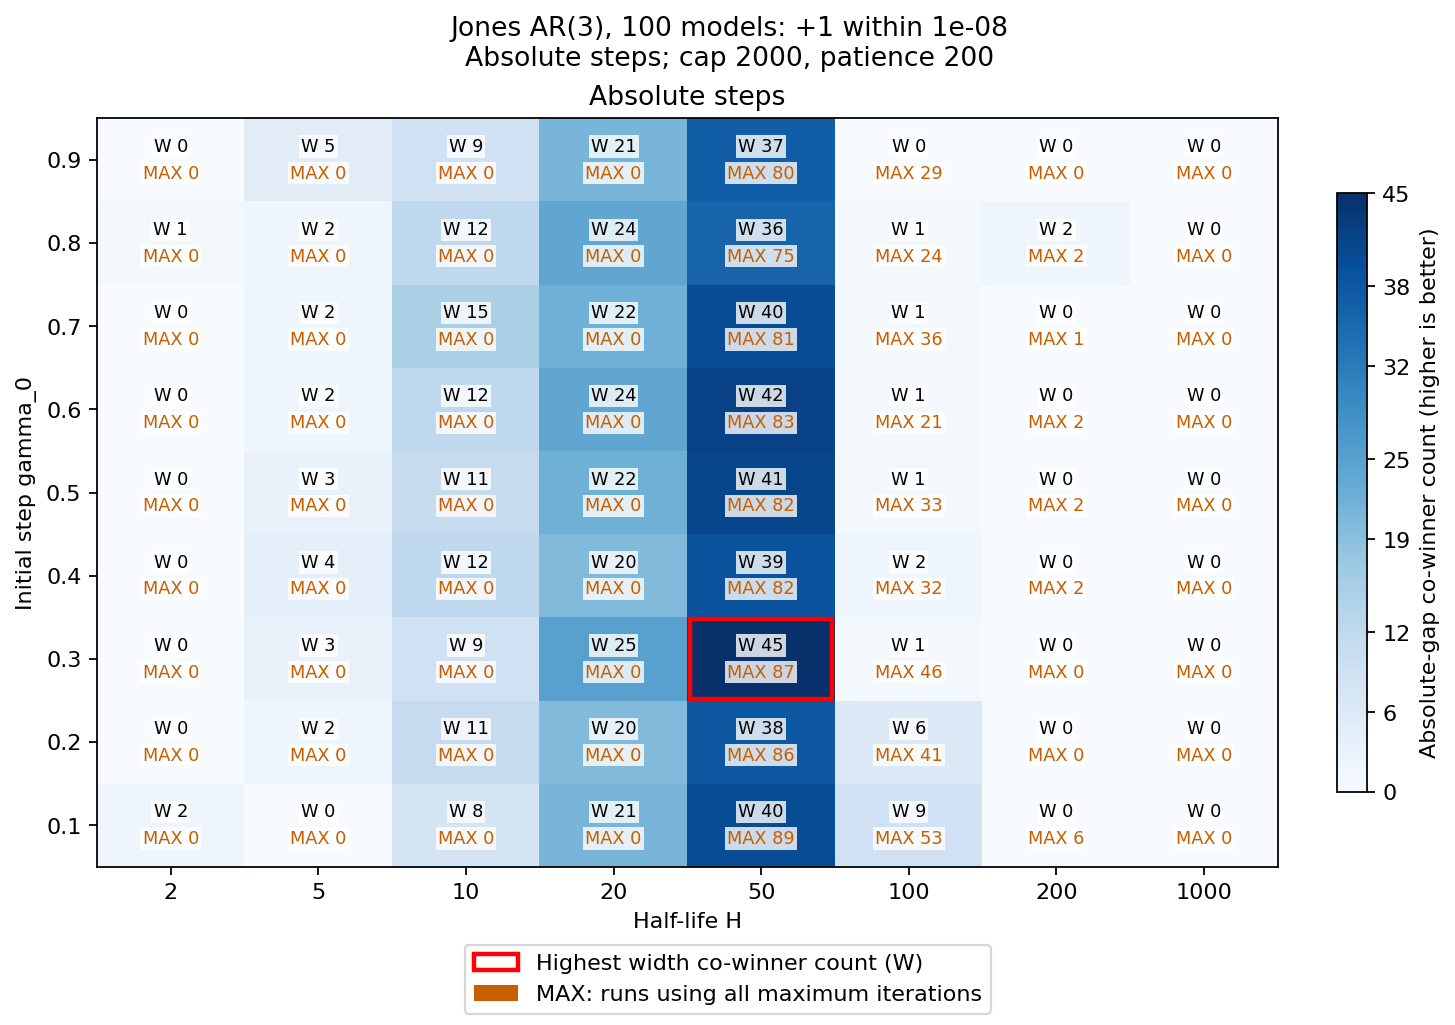

In [8]:
jones_win_figure_stem = f"02_fixed_random_absolute_width_and_iteration_counts_eps_{epsilon_win_tolerance:g}"
fig, jones_win_matrices = plot_tuning_matrices(
    jones_win_ranking, scale_grid, half_life_grid, metric="wins", iteration_limit_metric="iteration_limit_count", maximize=True, precision=0,
    title=(f"Jones AR(3), {number_of_coefficient_realizations} models: +1 within {epsilon_win_tolerance:g}\n"
           f"Absolute steps; cap {max_iterations}, patience {patience}"),
    colorbar_label="Absolute-gap co-winner count (higher is better)",
    filename=jones_win_figure_stem, pdf_directory=JONES_PDF_DIR, image_directory=JONES_IMAGE_DIR,
)
plt.show()
plt.close(fig)

In [9]:
with capture_output():
    print("Section 1 winners under the absolute-gap win-count rule:")
    for choice in jones_win_leaders.to_dict("records"):
        print(f"{choice['step_rule']}: scale={choice['step_value']:g}, H={choice['half_life']:g}, "
              f"beta={choice['beta']:.12g}; {int(choice['wins'])}/{number_of_coefficient_realizations} model wins.")
        print(f"Actual gamma0 range across models: [{choice['gamma0_min']:.12g}, {choice['gamma0_max']:.12g}].")
    print(f"One fixed u_0 throughout: {initial_direction}")
    print(f"PDF matrices: {JONES_PDF_DIR}")

## 2. Fixed random direction — normalized steps

Reuse the exact Jones coefficient vectors, innovation paths and fixed random `initial_direction` from Section 1. Change the initial step to $\gamma_0=s/L$, where $L$ is the exact Euclidean diameter of the empirical four-coordinate point cloud. Use the same scale and half-life grids, iteration cap and patience, with one start and stationarity-triggered restarts disabled. [Shared runner and diameter calculation](../ar_tools/tuning.py).

Pairing assertions check model inputs, seeds and width references against Section 1. The matrix shows width co-winner counts within this section's grid and orange counts of runs using the full iteration budget. Only width co-winner counts determine the selected configurations. [Counting implementation](../ar_tools/tuning.py).

In [10]:
with capture_output():
    jones_normalized_n_jobs = 4
    jones_normalized_configuration = {
        **jones_configuration,
        "experiment": "jones_fixed_random_normalized_no_restarts",
        "step_rules": ["diameter_normalized"],
        "stationarity_check": False, "max_restarts": 0,
        "diameter": "max_pairwise_euclidean_distance",
        "parallel_workers": jones_normalized_n_jobs,
    }
    jones_normalized_run_id = hashlib.sha256(
        repr(sorted(jones_normalized_configuration.items())).encode()
    ).hexdigest()[:16]
    JONES_NORMALIZED_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"jones_normalized_{jones_normalized_run_id}"
    JONES_NORMALIZED_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"jones_normalized_{jones_normalized_run_id}"
    for directory in (JONES_NORMALIZED_PDF_DIR, JONES_NORMALIZED_IMAGE_DIR):
        directory.mkdir(parents=True, exist_ok=True)

In [11]:
with capture_output():
    jones_normalized_experiment = tune_jones_ar_realizations(
        T, initial_direction, scale_grid, half_life_grid,
        replications=number_of_coefficient_realizations,
        coefficient_seed=jones_coefficient_seed, process_seed=jones_process_seed,
        burnin=burnin, iterations=max_iterations, patience=patience,
        improvement_tolerance=improvement_tolerance, optimizer_seed=optimizer_seed,
        progress=False, summarize=False, coefficient_diagnostics=False, stationarity_check=False, max_restarts=0,
        step_rule="diameter_normalized", n_jobs=jones_normalized_n_jobs,
    )
    jones_normalized_results = pd.DataFrame(jones_normalized_experiment["results"])
    jones_normalized_cases = pd.DataFrame(jones_normalized_experiment["cases"])
    jones_normalized_pairing_columns = [
        "replication", "T", "coefficient_seed", "process_seed", "phi_1", "phi_2", "phi_3",
        "pacf_1", "pacf_2", "pacf_3", "spectral_radius",
        "population_minimum_width", "empirical_true_direction_width",
    ]
    pd.testing.assert_frame_equal(
        jones_cases[jones_normalized_pairing_columns].sort_values("replication").reset_index(drop=True),
        jones_normalized_cases[jones_normalized_pairing_columns].sort_values("replication").reset_index(drop=True),
        check_exact=True,
    )
    np.testing.assert_allclose(
        jones_normalized_experiment["initial_direction"], initial_direction, atol=1e-15, rtol=0,
    )
    assert len(jones_normalized_cases) == number_of_coefficient_realizations
    assert len(jones_normalized_results) == number_of_coefficient_realizations * len(scale_grid) * len(half_life_grid)
    assert not jones_normalized_results.duplicated(["replication", "T", "candidate_id"]).any()
    assert jones_normalized_results["total_evaluations"].between(1, max_iterations).all()
    assert jones_normalized_results["selected_start"].eq(1).all()
    assert np.isfinite(jones_normalized_results["minimum_width"]).all()
    assert jones_normalized_results.groupby("replication")["cloud_diameter"].nunique().eq(1).all()
    np.testing.assert_allclose(
        jones_normalized_results["gamma0"] * jones_normalized_results["cloud_diameter"],
        jones_normalized_results["step_value"], rtol=2e-15, atol=0,
    )

In [12]:
with capture_output():
    jones_normalized_width_counts, jones_normalized_ranking, jones_normalized_leaders = summarize_width_grid(
        jones_normalized_results,
    )

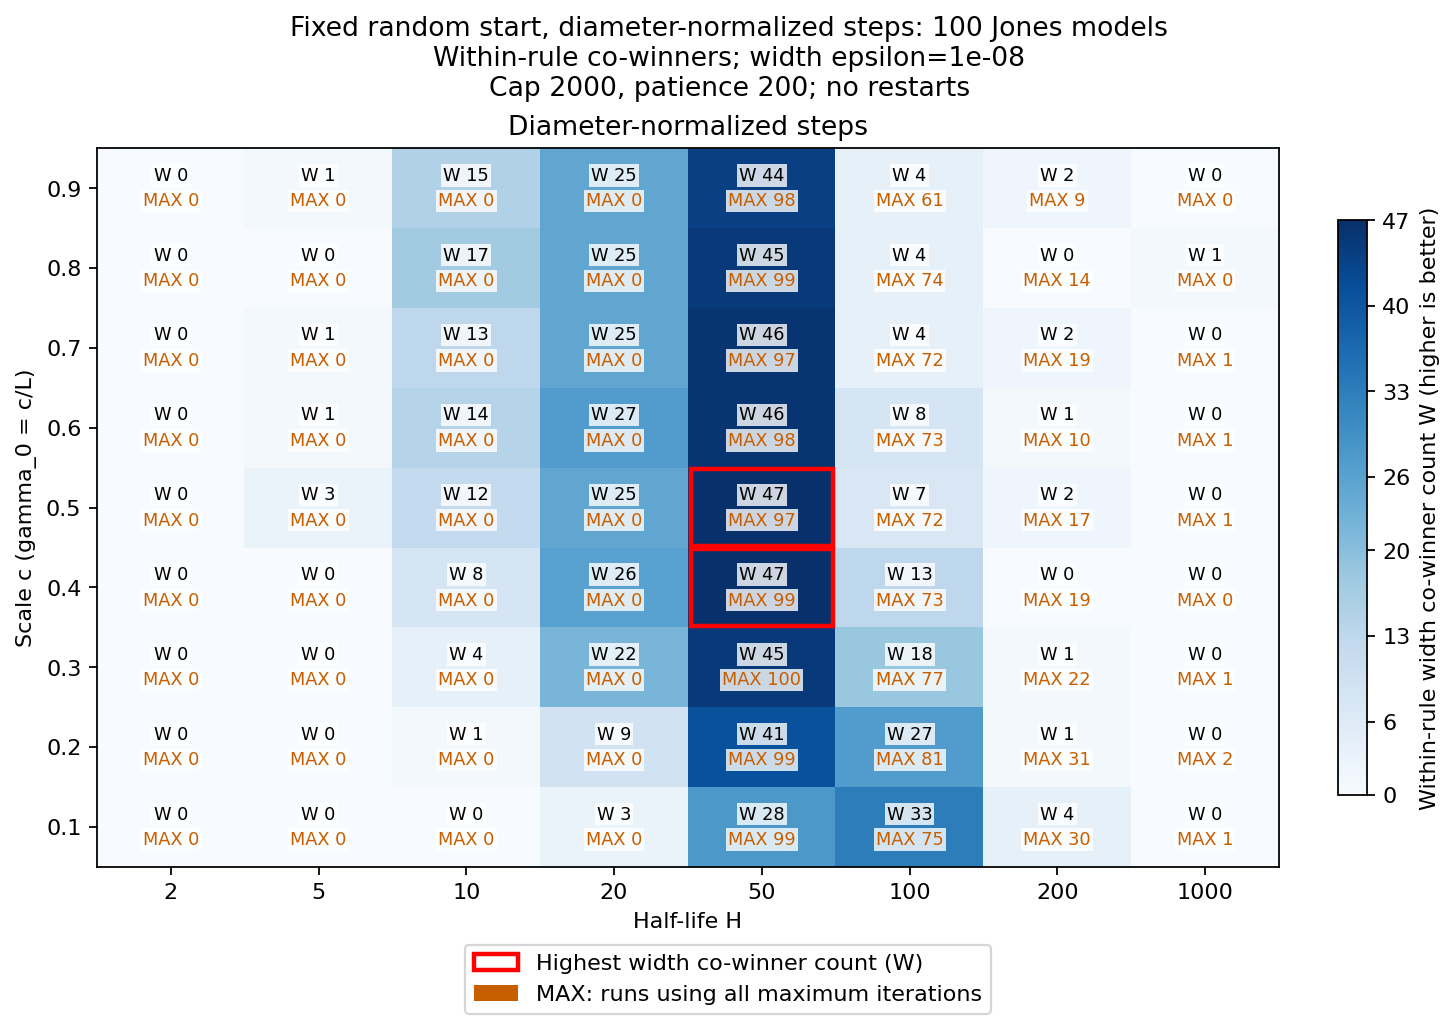

In [13]:
jones_normalized_figure_stem = f"11_fixed_random_normalized_width_and_iteration_counts_eps_{epsilon_win_tolerance:g}"
fig, jones_normalized_win_matrices = plot_tuning_matrices(
    jones_normalized_ranking, scale_grid, half_life_grid,
    metric="wins", iteration_limit_metric="iteration_limit_count", maximize=True, precision=0,
    title=(f"Fixed random start, diameter-normalized steps: {number_of_coefficient_realizations} Jones models\n"
           f"Within-rule co-winners; width epsilon={epsilon_win_tolerance:g}\n"
           f"Cap {max_iterations}, patience {patience}; no restarts"),
    colorbar_label="Within-rule width co-winner count W (higher is better)",
    filename=jones_normalized_figure_stem,
    pdf_directory=JONES_NORMALIZED_PDF_DIR, image_directory=JONES_NORMALIZED_IMAGE_DIR,
)
plt.show()
plt.close(fig)

## 3. Direction e1 — absolute steps

Reuse the exact Jones coefficient vectors and innovation paths from Section 1. Use the deterministic starting direction $e_1=(1,0,0,0)$ and the **absolute initial step $\gamma_0=s$**. Search the same scale and half-life grid: 72 configurations with the default settings. [Shared runner](../ar_tools/tuning.py).

Use the shared iteration cap, patience and zero improvement tolerance, with one start and stationarity-triggered restarts disabled. The settings cell prepares the $e_1$ direction and export configuration shared with Section 4. Each section runs and displays its own step rule separately. [Optimizer](../ar_tools/descent.py).

Select using width co-winner counts within this section's grid. Orange MAX counts show runs that used all allowed iterations and do not affect selection. [Counting implementation](../ar_tools/tuning.py).

In [14]:
with capture_output():
    # Refresh shared helpers when rerunning this section in an existing kernel.
    tuning_tools = importlib.reload(tuning_tools)
    tune_jones_ar_realizations = tuning_tools.tune_jones_ar_realizations
    with plt.rc_context():
        tuning_plot_tools = importlib.reload(tuning_plot_tools)
        plot_tuning_matrices = tuning_plot_tools.plot_tuning_matrices

    e1_initial_direction = np.zeros(embedding_dimension, dtype=float)
    e1_initial_direction[0] = 1.0
    e1_step_rules = ("absolute", "diameter_normalized")
    e1_n_jobs = 4
    e1_configuration = {
        **jones_configuration,
        "experiment": "experiment_4_jones_ar3_e1",
        "initial_direction": e1_initial_direction.tolist(),
        "step_rules": list(e1_step_rules),
        "stationarity_check": False, "max_restarts": 0,
        "diameter": "max_pairwise_euclidean_distance",
        "parallel_workers": e1_n_jobs,
        "source_sha256": hashlib.sha256(b"".join(
            (AR_CODE_DIR / "ar_tools" / name).read_bytes()
            for name in ["functions.py", "innovations.py", "descent.py", "tuning.py", "tuning_plots.py"]
        )).hexdigest(),
    }
    e1_run_id = hashlib.sha256(repr(sorted(e1_configuration.items())).encode()).hexdigest()[:16]
    E1_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"experiment4_e1_{e1_run_id}"
    E1_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"experiment4_e1_{e1_run_id}"
    for directory in (E1_PDF_DIR, E1_IMAGE_DIR):
        directory.mkdir(parents=True, exist_ok=True)
    print(f"Experiment 4: {number_of_coefficient_realizations} original Jones models and paths; u_0={e1_initial_direction}.")
    print(f"Rules: gamma0=s and gamma0=s/L; cap={max_iterations}, patience={patience}; one start, no restarts.")
    print(f"Coefficient seed={jones_coefficient_seed}; process seed={jones_process_seed}; run={e1_run_id}.")

In [15]:
with capture_output():
    e1_experiments = {}
    e1_pairing_columns = [
        "replication", "T", "coefficient_seed", "process_seed", "phi_1", "phi_2", "phi_3",
        "pacf_1", "pacf_2", "pacf_3", "spectral_radius",
        "population_minimum_width", "empirical_true_direction_width",
    ]
    for e1_rule in ("absolute",):
        print(f"\nExperiment 4 — {e1_rule}", flush=True)
        e1_experiments[e1_rule] = tune_jones_ar_realizations(
            T, e1_initial_direction, scale_grid, half_life_grid,
            replications=number_of_coefficient_realizations,
            coefficient_seed=jones_coefficient_seed, process_seed=jones_process_seed,
            burnin=burnin, iterations=max_iterations, patience=patience,
            improvement_tolerance=improvement_tolerance, optimizer_seed=optimizer_seed,
            progress=True, summarize=False, coefficient_diagnostics=False, stationarity_check=False, max_restarts=0,
            step_rule=e1_rule, n_jobs=e1_n_jobs,
        )
        e1_rule_cases = pd.DataFrame(e1_experiments[e1_rule]["cases"])
        pd.testing.assert_frame_equal(
            jones_cases[e1_pairing_columns].sort_values("replication").reset_index(drop=True),
            e1_rule_cases[e1_pairing_columns].sort_values("replication").reset_index(drop=True),
            check_exact=True,
        )
        np.testing.assert_array_equal(e1_experiments[e1_rule]["initial_direction"], e1_initial_direction)

    e1_absolute_results = pd.DataFrame(e1_experiments["absolute"]["results"])

### 3.1 Width co-winner counts and iteration usage

In [16]:
with capture_output():
    e1_absolute_width_counts, e1_absolute_ranking, e1_absolute_leaders = summarize_width_grid(
        e1_absolute_results,
    )

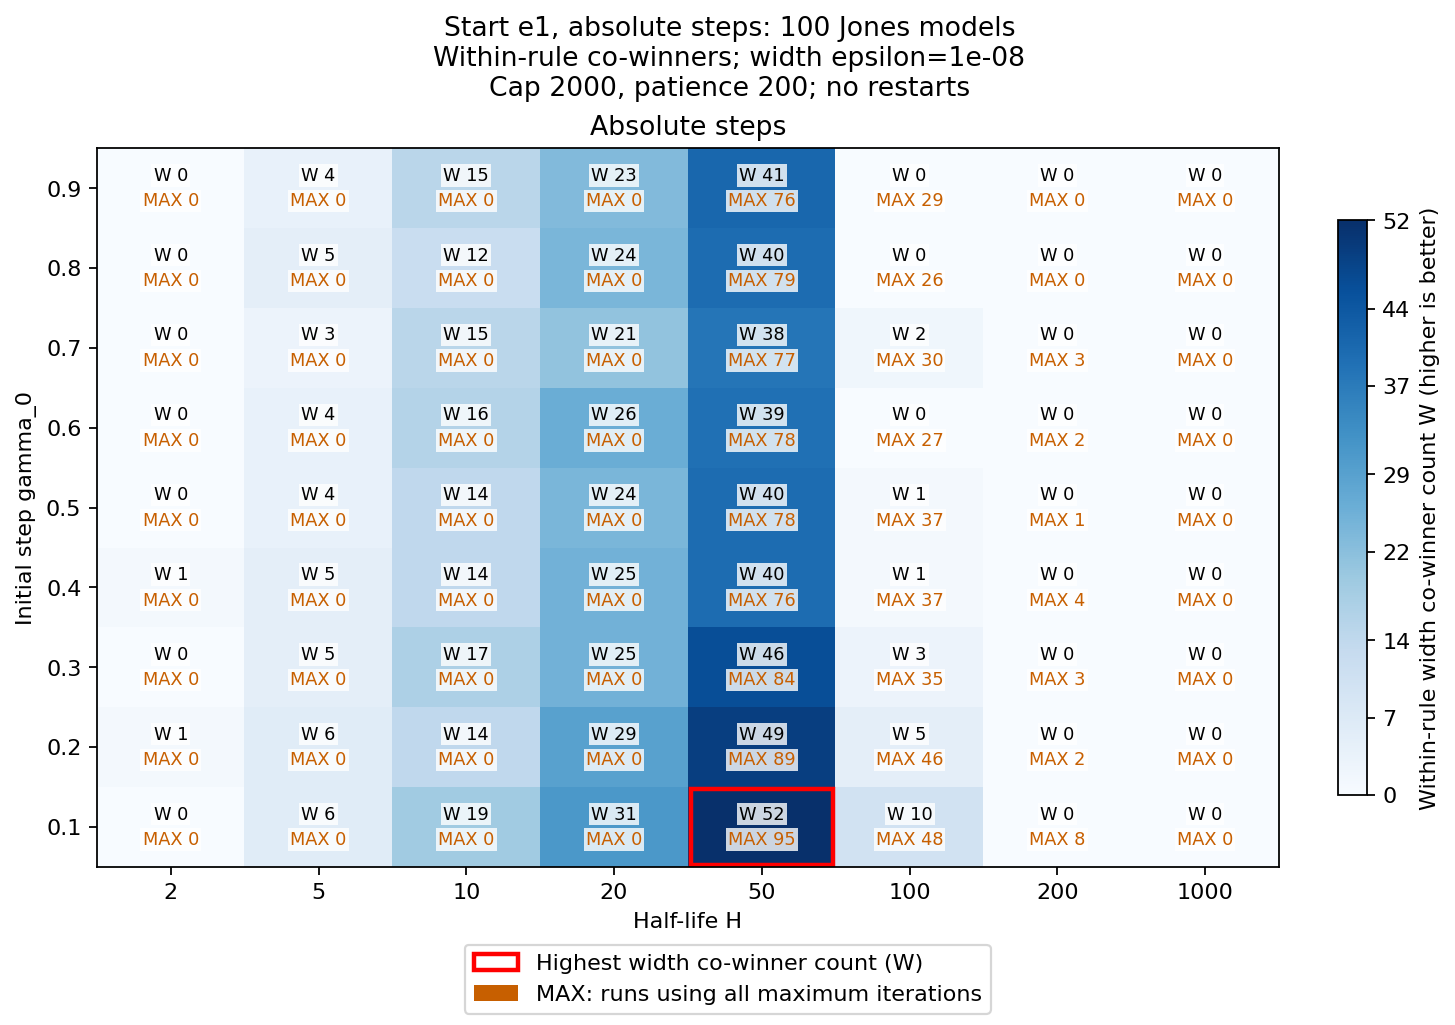

In [17]:
e1_absolute_figure_stem = f"10_e1_absolute_width_and_iteration_counts_eps_{epsilon_win_tolerance:g}"
fig, e1_absolute_win_matrices = plot_tuning_matrices(
    e1_absolute_ranking, scale_grid, half_life_grid,
    metric="wins", iteration_limit_metric="iteration_limit_count", maximize=True, precision=0,
    title=(f"Start e1, absolute steps: {number_of_coefficient_realizations} Jones models\n"
           f"Within-rule co-winners; width epsilon={epsilon_win_tolerance:g}\n"
           f"Cap {max_iterations}, patience {patience}; no restarts"),
    colorbar_label="Within-rule width co-winner count W (higher is better)",
    filename=e1_absolute_figure_stem, pdf_directory=E1_PDF_DIR, image_directory=E1_IMAGE_DIR,
)
plt.show()
plt.close(fig)

## 4. Direction e1 — normalized steps

Reuse the models, paths, deterministic $e_1$ direction and shared settings from Sections 1 and 3. Change the initial step to **$\gamma_0=s/L$**, where $L$ is the exact Euclidean diameter of each empirical point cloud. The scale and half-life grid again has 72 configurations with the default settings. [Shared runner and diameter calculation](../ar_tools/tuning.py).

Use one start, the same iteration cap and patience, and stationarity-triggered restarts disabled. Select using width co-winner counts within this section's grid. Orange MAX counts show runs using all allowed iterations. Section 5 combines the completed results from all four experiments. [Optimizer](../ar_tools/descent.py), [counting implementation](../ar_tools/tuning.py).

In [18]:
with capture_output():
    for e1_rule in ("diameter_normalized",):
        print(f"\nExperiment 4 — {e1_rule}", flush=True)
        e1_experiments[e1_rule] = tune_jones_ar_realizations(
            T, e1_initial_direction, scale_grid, half_life_grid,
            replications=number_of_coefficient_realizations,
            coefficient_seed=jones_coefficient_seed, process_seed=jones_process_seed,
            burnin=burnin, iterations=max_iterations, patience=patience,
            improvement_tolerance=improvement_tolerance, optimizer_seed=optimizer_seed,
            progress=True, summarize=False, coefficient_diagnostics=False, stationarity_check=False, max_restarts=0,
            step_rule=e1_rule, n_jobs=e1_n_jobs,
        )
        e1_rule_cases = pd.DataFrame(e1_experiments[e1_rule]["cases"])
        pd.testing.assert_frame_equal(
            jones_cases[e1_pairing_columns].sort_values("replication").reset_index(drop=True),
            e1_rule_cases[e1_pairing_columns].sort_values("replication").reset_index(drop=True),
            check_exact=True,
        )
        np.testing.assert_array_equal(e1_experiments[e1_rule]["initial_direction"], e1_initial_direction)

    e1_normalized_results = pd.DataFrame(e1_experiments["diameter_normalized"]["results"])

### 4.1 Width co-winner counts and iteration usage

In [19]:
with capture_output():
    e1_normalized_width_counts, e1_normalized_ranking, e1_normalized_leaders = summarize_width_grid(
        e1_normalized_results,
    )

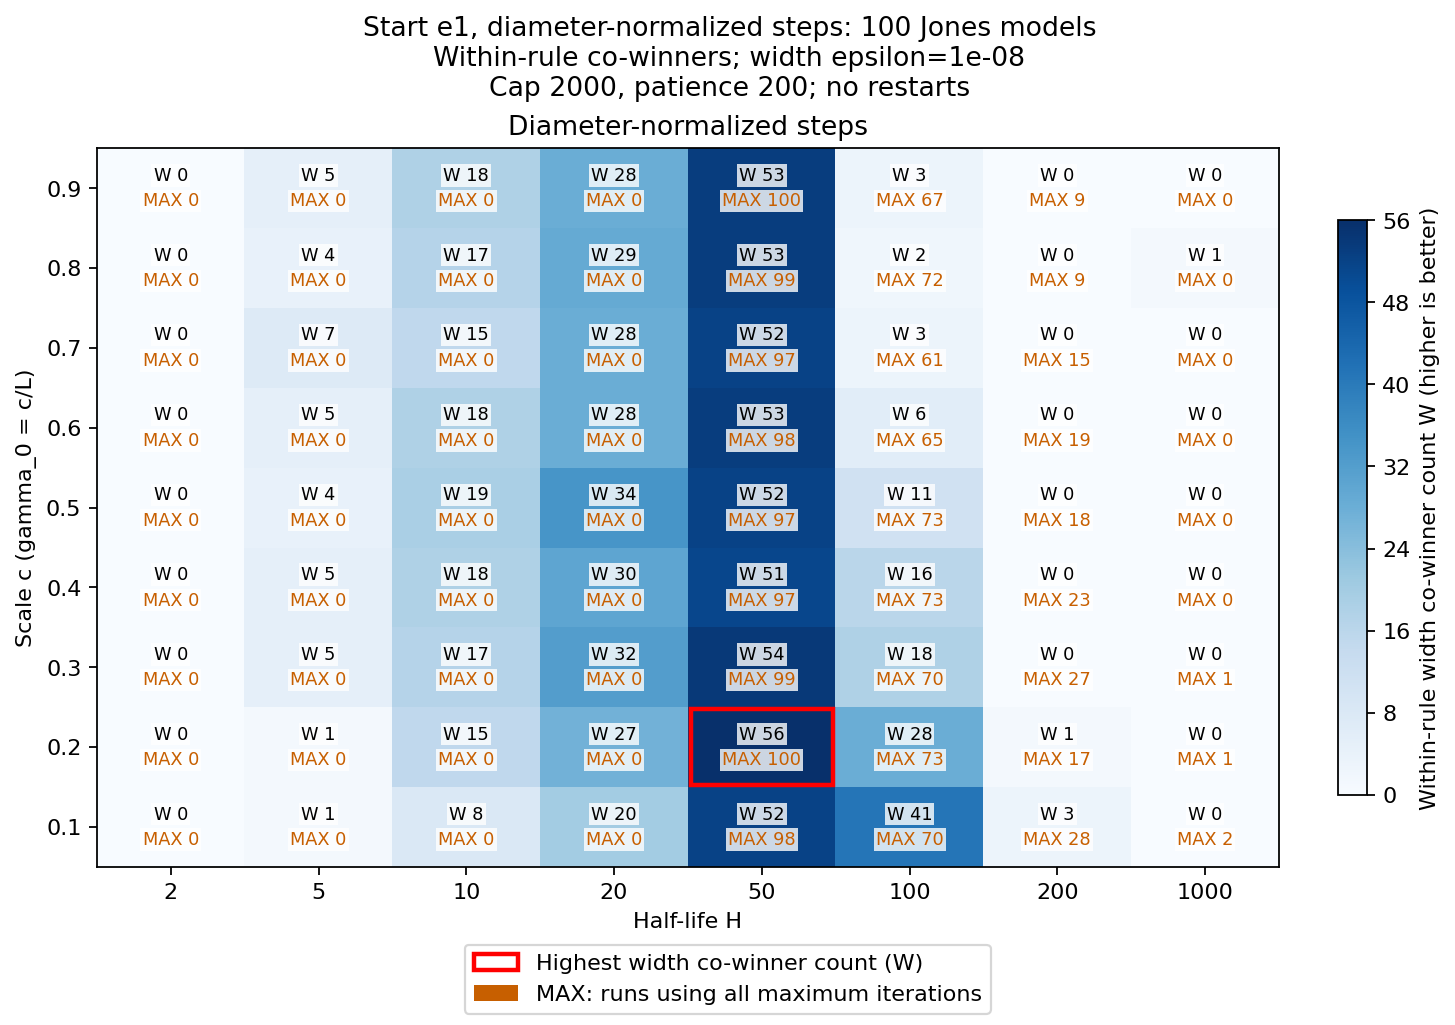

In [20]:
e1_normalized_figure_stem = f"10_e1_diameter_normalized_width_and_iteration_counts_eps_{epsilon_win_tolerance:g}"
fig, e1_normalized_win_matrices = plot_tuning_matrices(
    e1_normalized_ranking, scale_grid, half_life_grid,
    metric="wins", iteration_limit_metric="iteration_limit_count", maximize=True, precision=0,
    title=(f"Start e1, diameter-normalized steps: {number_of_coefficient_realizations} Jones models\n"
           f"Within-rule co-winners; width epsilon={epsilon_win_tolerance:g}\n"
           f"Cap {max_iterations}, patience {patience}; no restarts"),
    colorbar_label="Within-rule width co-winner count W (higher is better)",
    filename=e1_normalized_figure_stem, pdf_directory=E1_PDF_DIR, image_directory=E1_IMAGE_DIR,
)
plt.show()
plt.close(fig)

## 5. Common comparison of all four variants

This section reuses the completed results from Sections 1–4 and runs no further descents. It assembles the paired results, computes a supporting width-only comparison of the two $e_1$ variants, and then recomputes width co-winner counts across **all four grids together** for the final two-by-two figure. [Counting implementation](../ar_tools/tuning.py).

The final figure has starting directions as rows and step rules as columns. Each cell shows W (width co-winner count against the common reference) and orange MAX (runs using all allowed iterations). All panels use the same width-count color scale. Red boxes identify all configurations with the highest width count across the four grids. MAX never enters selection.

### 5.1 Assemble results and verify the paired design


In [21]:
with capture_output():
    e1_results = pd.concat([
        pd.DataFrame(e1_experiments[rule]["results"]) for rule in e1_step_rules
    ], ignore_index=True)
    e1_expected_per_rule = number_of_coefficient_realizations * len(scale_grid) * len(half_life_grid)
    assert len(e1_results) == 2 * e1_expected_per_rule
    assert e1_results.groupby("step_rule").size().eq(e1_expected_per_rule).all()
    assert not e1_results.duplicated(["replication", "T", "candidate_id"]).any()
    assert e1_results["total_evaluations"].between(1, max_iterations).all()
    assert e1_results["selected_start"].eq(1).all()
    assert np.isfinite(e1_results["minimum_width"]).all()
    e1_scaled_rows = e1_results.loc[e1_results["step_rule"].eq("diameter_normalized")]
    assert e1_scaled_rows.groupby("replication")["cloud_diameter"].nunique().eq(1).all()
    np.testing.assert_allclose(
        e1_scaled_rows["gamma0"] * e1_scaled_rows["cloud_diameter"],
        e1_scaled_rows["step_value"], rtol=2e-15, atol=0,
    )
    np.testing.assert_array_equal(
        e1_results.loc[e1_results["step_rule"].eq("absolute"), "gamma0"],
        e1_results.loc[e1_results["step_rule"].eq("absolute"), "step_value"],
    )
    print(f"\nCompleted {len(e1_results):,} configurations on the same {number_of_coefficient_realizations} models and paths.")
    print("Exact model coefficients, partial autocorrelations, seeds and reference widths match original Experiment 3 for both rules.")
    print(f"Total evaluated directions: {int(e1_results['total_evaluations'].sum()):,}.")

### 5.2 Supporting comparison of the two e1 variants

Within-rule counts use different reference minima. Recompute width co-winner counts over both $e_1$ grids together (144 configurations by default) on the same models. Retain every configuration tied for the highest count. The final figure below uses the broader four-variant reference. [Counting implementation](../ar_tools/tuning.py).

In [22]:
with capture_output():
    e1_common_width_counts, e1_common_ranking, e1_common_leaders = summarize_width_grid(e1_results)

### 5.3 Common reference across all four variants

Rows are **fixed random direction** and **$e_1$**; columns are **absolute steps** and **diameter-normalized steps**. All variants share models, paths, iteration cap and patience. [Shared runner](../ar_tools/tuning.py).

Recompute width co-winner credits against **all four grids together** (288 configurations per path by default). Each configuration is identified by initialization, step rule, scale and half-life. All configurations within the width tolerance receive +1, and every tied overall leader receives a red outline. This common reference differs from the individual sections' reference minima. [Counting rule](../ar_tools/tuning.py), `summarize_configuration_wins`.

Black W values and the background color show width co-winner counts. Orange MAX values count runs using all `max_iterations` and remain identical to their corresponding individual matrices; no additional descent is run. MAX does not affect the winner.

In [23]:
with capture_output():
    factorial_results = pd.concat([
        jones_results.assign(initialization="fixed_random"),
        jones_normalized_results.assign(initialization="fixed_random"),
        e1_results.assign(initialization="e1"),
    ], ignore_index=True)
    factorial_results["within_variant_candidate_id"] = factorial_results["candidate_id"]
    factorial_results["candidate_id"] = factorial_results["initialization"] + "::" + factorial_results["candidate_id"]
    factorial_grid_size = len(scale_grid) * len(half_life_grid)
    assert len(factorial_results) == 4 * factorial_grid_size * number_of_coefficient_realizations
    assert factorial_results["candidate_id"].nunique() == 4 * factorial_grid_size
    assert not factorial_results.duplicated(["replication", "T", "candidate_id"]).any()
    assert factorial_results.groupby(["replication", "T"]).size().eq(4 * factorial_grid_size).all()

    factorial_width_counts, factorial_ranking, factorial_width_leaders = summarize_width_grid(factorial_results)
    factorial_labels = factorial_results[["candidate_id", "initialization"]].drop_duplicates()
    factorial_ranking = factorial_ranking.merge(factorial_labels, on="candidate_id", validate="one_to_one")
    factorial_width_leaders = factorial_ranking.loc[
        factorial_ranking["wins"].eq(factorial_ranking["wins"].max())
    ].copy()

    factorial_configuration = {
        **jones_configuration,
        "experiment": "jones_start_step_2x2_common_reference",
        "initial_directions": {"fixed_random": initial_direction.tolist(), "e1": e1_initial_direction.tolist()},
        "step_rules": ["absolute", "diameter_normalized"],
        "stationarity_check": False, "max_restarts": 0,
        "reference": "all_four_start_step_grids",
    }
    factorial_run_id = hashlib.sha256(repr(sorted(factorial_configuration.items())).encode()).hexdigest()[:16]
    FACTORIAL_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"factorial_2x2_{factorial_run_id}"
    FACTORIAL_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"factorial_2x2_{factorial_run_id}"
    for directory in (FACTORIAL_PDF_DIR, FACTORIAL_IMAGE_DIR):
        directory.mkdir(parents=True, exist_ok=True)

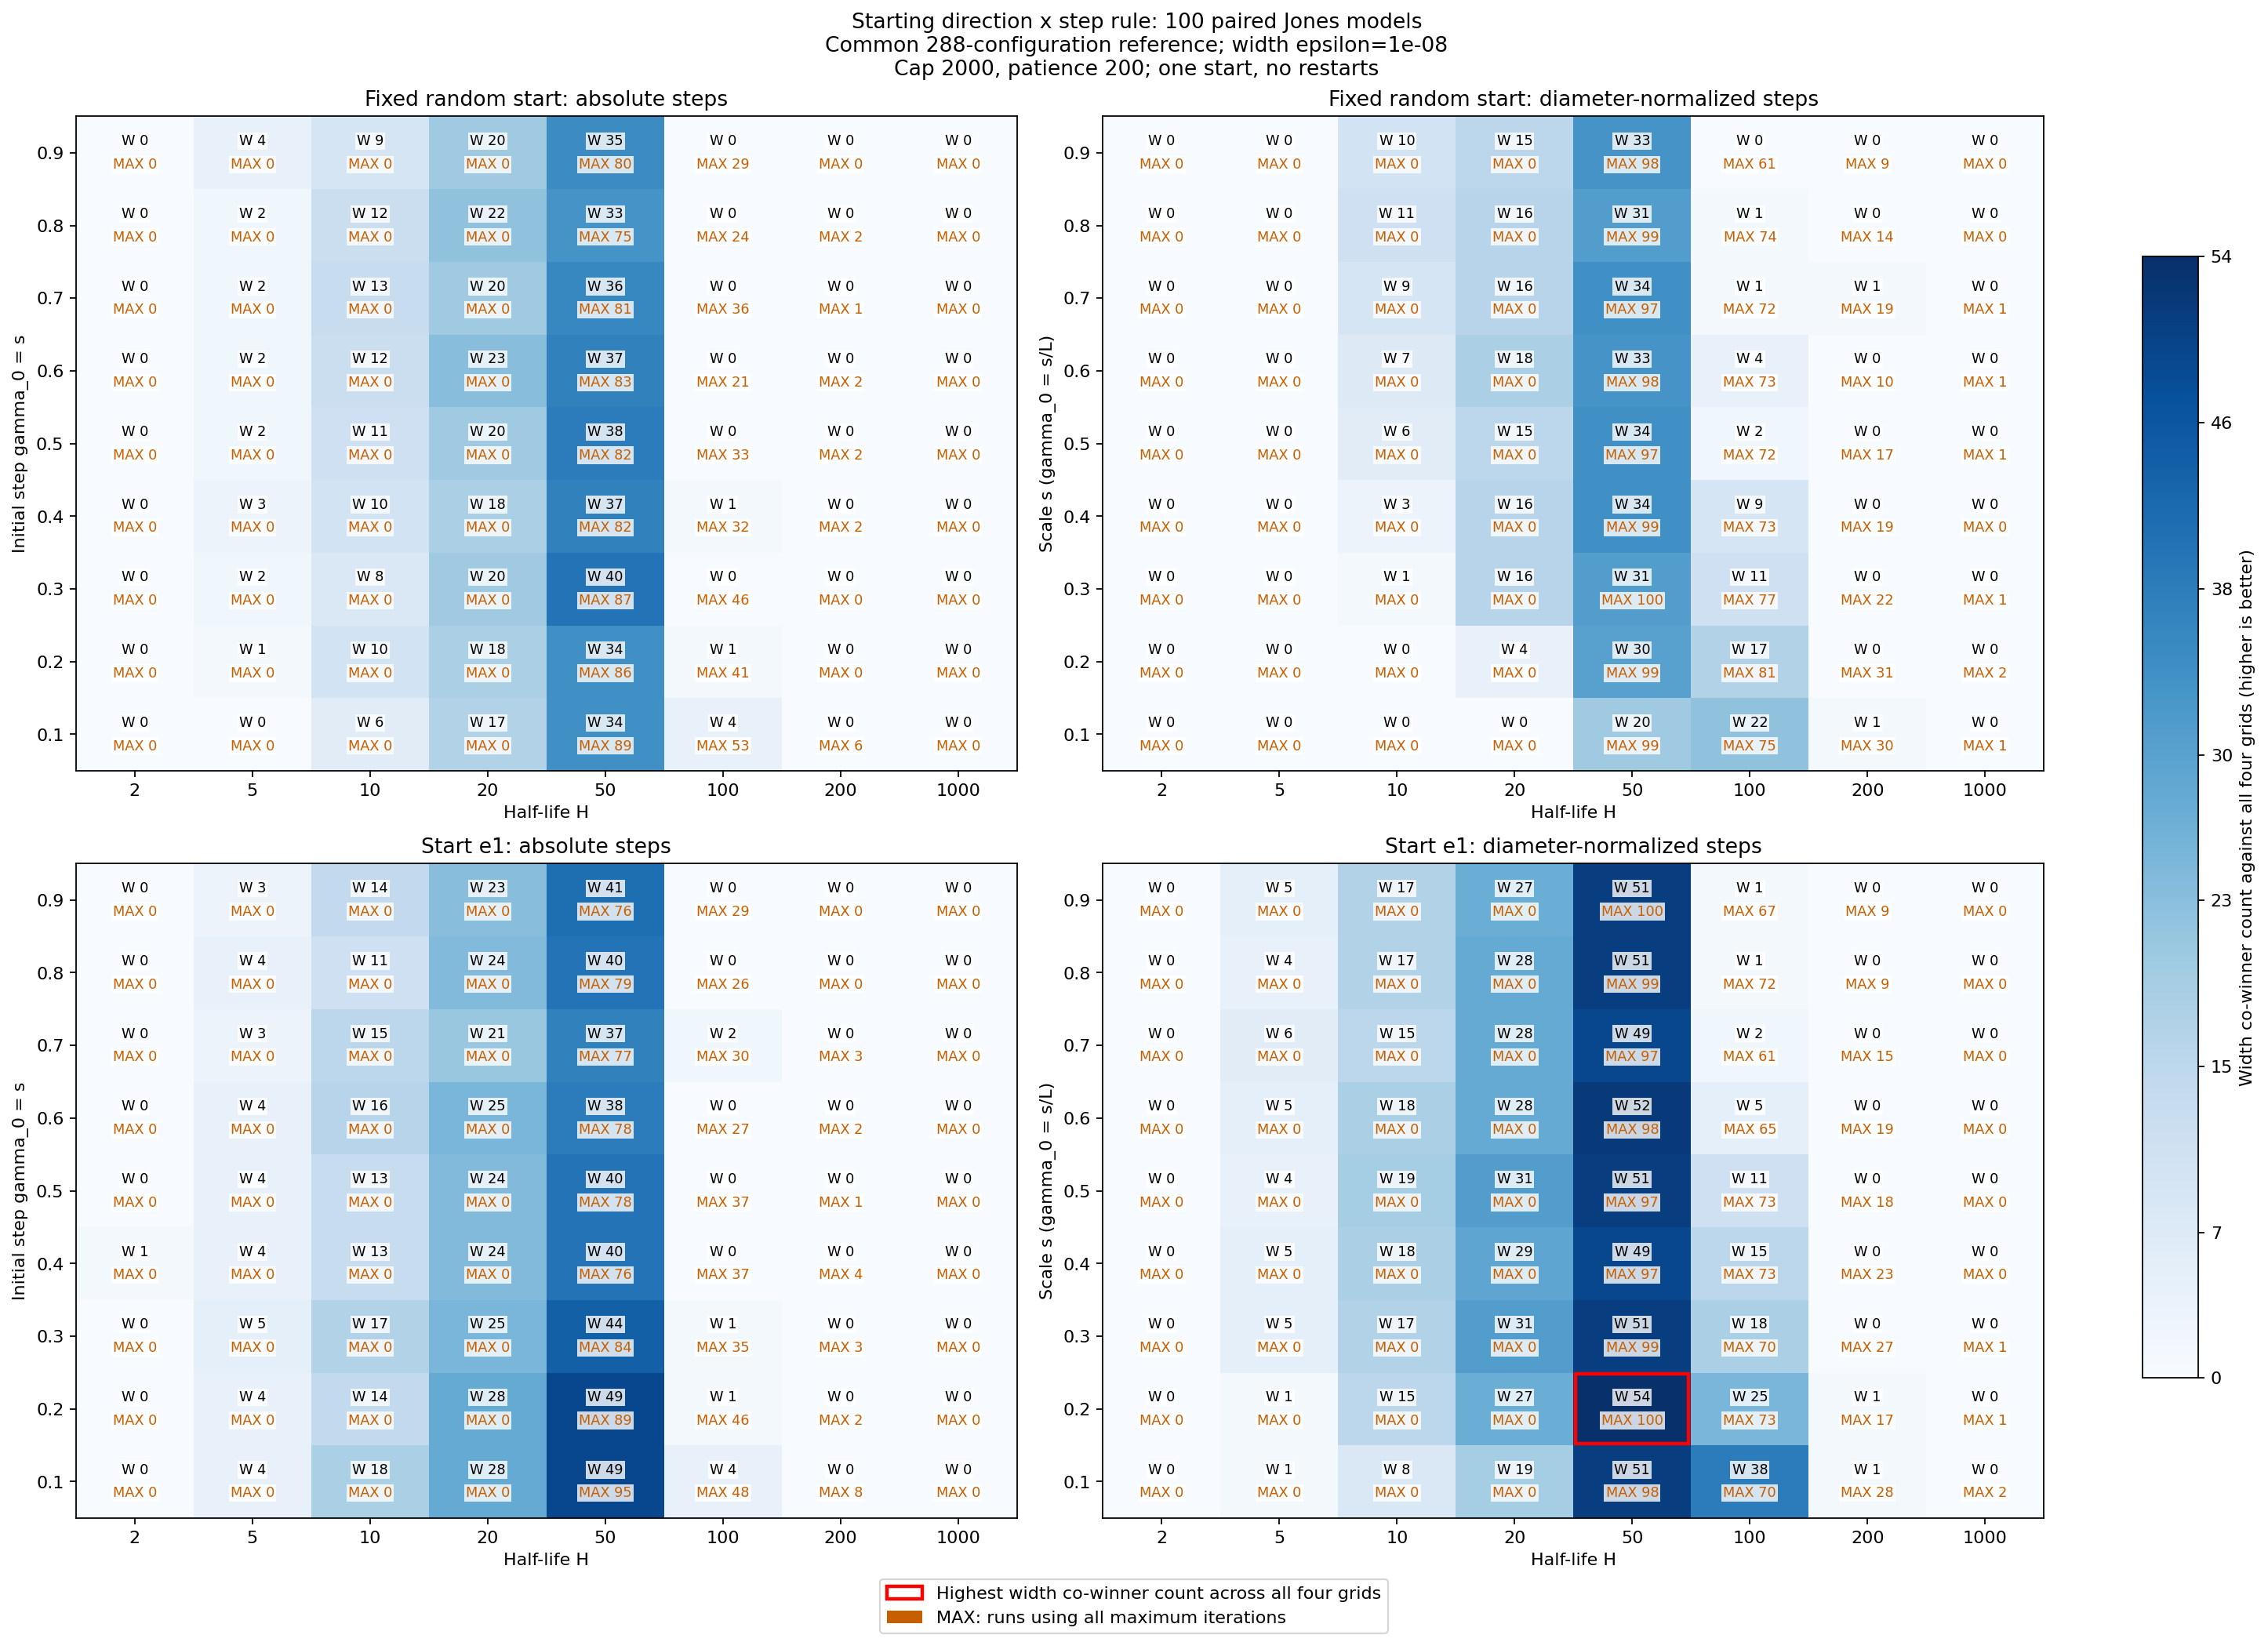

In [24]:
from matplotlib.patches import Patch, Rectangle
from Code.Code_AR_processes.ar_tools.plotting_functions import save_figure
from Code.Code_AR_processes.ar_tools.tuning_plots import annotate_tuning_cell, ITERATION_COUNT_COLOR

factorial_win_matrices = {}
fig, factorial_axes = plt.subplots(2, 2, figsize=(18, 13), constrained_layout=True)
factorial_color_max = max(1, int(factorial_ranking["wins"].max()))
factorial_best_width = factorial_ranking["wins"].max()
for factorial_row, factorial_initialization in enumerate(("fixed_random", "e1")):
    for factorial_column, factorial_rule in enumerate(("absolute", "diameter_normalized")):
        factorial_ax = factorial_axes[factorial_row, factorial_column]
        factorial_panel = factorial_ranking.loc[
            factorial_ranking["initialization"].eq(factorial_initialization)
            & factorial_ranking["step_rule"].eq(factorial_rule)
        ]
        factorial_width_matrix = factorial_panel.pivot(index="step_value", columns="half_life", values="wins").reindex(
            index=scale_grid, columns=half_life_grid,
        )
        factorial_iteration_matrix = factorial_panel.pivot(
            index="step_value", columns="half_life", values="iteration_limit_count",
        ).reindex(index=scale_grid, columns=half_life_grid)
        assert factorial_width_matrix.notna().all().all()
        factorial_win_matrices[(factorial_initialization, factorial_rule)] = factorial_width_matrix
        factorial_image = factorial_ax.imshow(
            factorial_width_matrix.to_numpy(), origin="lower", aspect="auto", cmap="Blues",
            vmin=0, vmax=factorial_color_max,
        )
        for factorial_i in range(len(scale_grid)):
            for factorial_j in range(len(half_life_grid)):
                factorial_w = int(factorial_width_matrix.iloc[factorial_i, factorial_j])
                factorial_max = int(factorial_iteration_matrix.iloc[factorial_i, factorial_j])
                annotate_tuning_cell(
                    factorial_ax, factorial_j, factorial_i, f"W {factorial_w}", factorial_max,
                )
                if factorial_w == factorial_best_width:
                    factorial_ax.add_patch(Rectangle(
                        (factorial_j - .48, factorial_i - .48), .96, .96,
                        fill=False, edgecolor="red", linewidth=2,
                    ))
        factorial_start_label = "Fixed random start" if factorial_initialization == "fixed_random" else "Start e1"
        factorial_step_label = "absolute steps" if factorial_rule == "absolute" else "diameter-normalized steps"
        factorial_ax.set(
            xticks=np.arange(len(half_life_grid)), xticklabels=[f"{h:g}" for h in half_life_grid],
            yticks=np.arange(len(scale_grid)), yticklabels=[f"{s:g}" for s in scale_grid],
            xlabel="Half-life H",
            ylabel="Initial step gamma_0 = s" if factorial_rule == "absolute" else "Scale s (gamma_0 = s/L)",
            title=f"{factorial_start_label}: {factorial_step_label}",
        )
fig.suptitle(
    f"Starting direction x step rule: {number_of_coefficient_realizations} paired Jones models\n"
    f"Common {4 * factorial_grid_size}-configuration reference; width epsilon={epsilon_win_tolerance:g}\n"
    f"Cap {max_iterations}, patience {patience}; one start, no restarts",
)
factorial_colorbar = fig.colorbar(
    factorial_image, ax=factorial_axes.ravel().tolist(), shrink=.8,
    label="Width co-winner count against all four grids (higher is better)",
)
factorial_colorbar.set_ticks(np.unique(np.linspace(
    0, factorial_color_max, min(factorial_color_max + 1, 8), dtype=int,
)))
fig.legend(handles=[
    Patch(fill=False, edgecolor="red", linewidth=2, label="Highest width co-winner count across all four grids"),
    Patch(facecolor=ITERATION_COUNT_COLOR, edgecolor="none", label="MAX: runs using all maximum iterations"),
], loc="outside lower center", ncol=1)
factorial_figure_stem = "12_starting_direction_step_rule_2x2_width_and_iteration_counts"
save_figure(fig, factorial_figure_stem, pdf_directory=FACTORIAL_PDF_DIR, image_directory=FACTORIAL_IMAGE_DIR)
plt.show()
plt.close(fig)